Using device: cuda
Model: ResNet-50  (comparison baseline)
Classes: ['acne', 'hyperpigmentation', 'Nail_psoriasis', 'SJS-TEN', 'Vitiligo']

Total images found: 6348
label
Nail_psoriasis       1500
Vitiligo             1500
SJS-TEN              1500
acne                 1148
hyperpigmentation     700

Split -> train: 4443  val: 952  test: 953

Class counts (train): {'acne': 803, 'hyperpigmentation': 490, 'Nail_psoriasis': 1050, 'SJS-TEN': 1050, 'Vitiligo': 1050}
Class weights:        {'acne': 1.107, 'hyperpigmentation': 1.813, 'Nail_psoriasis': 0.846, 'SJS-TEN': 0.846, 'Vitiligo': 0.846}
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 166MB/s] 



Model: ResNet-50  |  Total params: 24,033,861  |  Trainable: 15,490,565

TRAINING — ResNet-50  (layer4 + head unfrozen, StepLR)
  Ep 01/20 | loss 1.2072/0.6668 | acc 0.5505/0.8025 | prec 0.8006 rec 0.8018 f1 0.7963 | lr 1.00e-03 | 29s  [saved]
  Ep 02/20 | loss 0.4955/0.2891 | acc 0.8262/0.9097 | prec 0.9040 rec 0.9120 f1 0.9073 | lr 1.00e-03 | 21s  [saved]
  Ep 03/20 | loss 0.2809/0.2013 | acc 0.9048/0.9391 | prec 0.9432 rec 0.9359 f1 0.9392 | lr 1.00e-03 | 21s  [saved]
  Ep 04/20 | loss 0.1829/0.1254 | acc 0.9370/0.9653 | prec 0.9627 rec 0.9643 f1 0.9634 | lr 1.00e-03 | 22s  [saved]
  Ep 05/20 | loss 0.1234/0.1080 | acc 0.9545/0.9695 | prec 0.9702 rec 0.9658 f1 0.9678 | lr 1.00e-03 | 22s  [saved]
  Ep 06/20 | loss 0.1023/0.0835 | acc 0.9640/0.9748 | prec 0.9709 rec 0.9733 f1 0.9720 | lr 1.00e-03 | 23s  [saved]
  Ep 07/20 | loss 0.0810/0.1017 | acc 0.9712/0.9727 | prec 0.9776 rec 0.9642 f1 0.9701 | lr 1.00e-04 | 23s
  Ep 08/20 | loss 0.0601/0.0756 | acc 0.9804/0.9758 | prec 0.9736 re

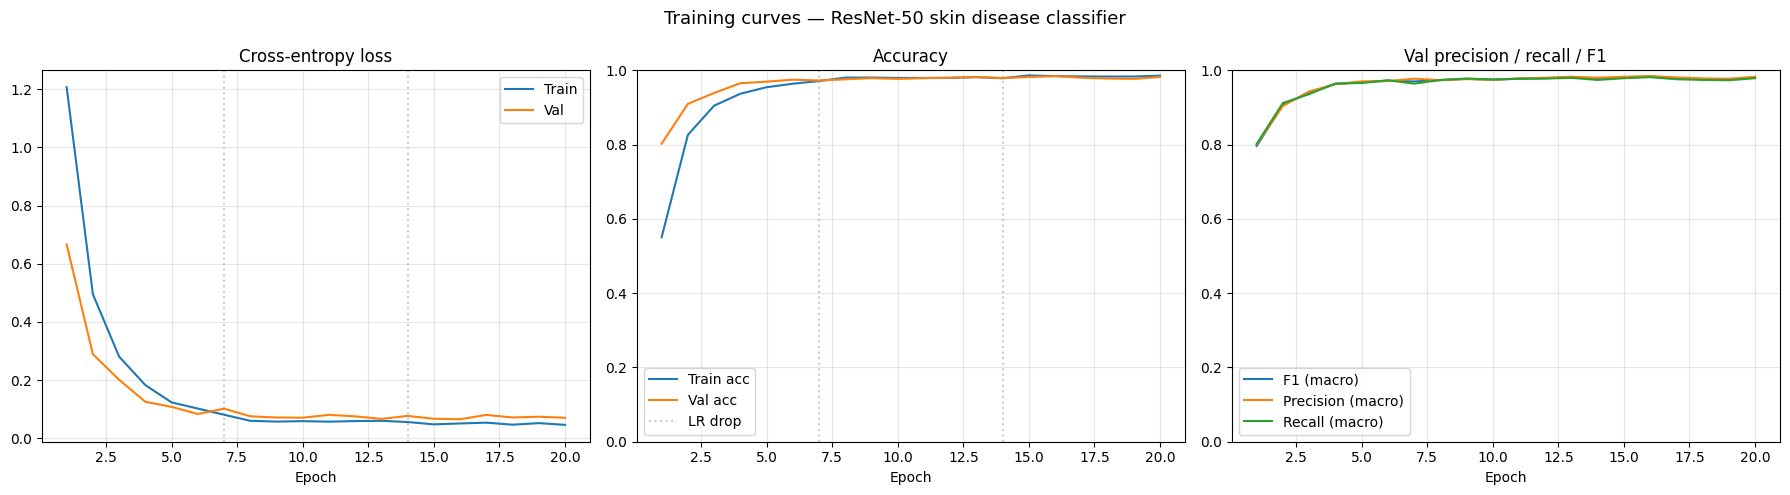

Saved r50_01_training_curves.png


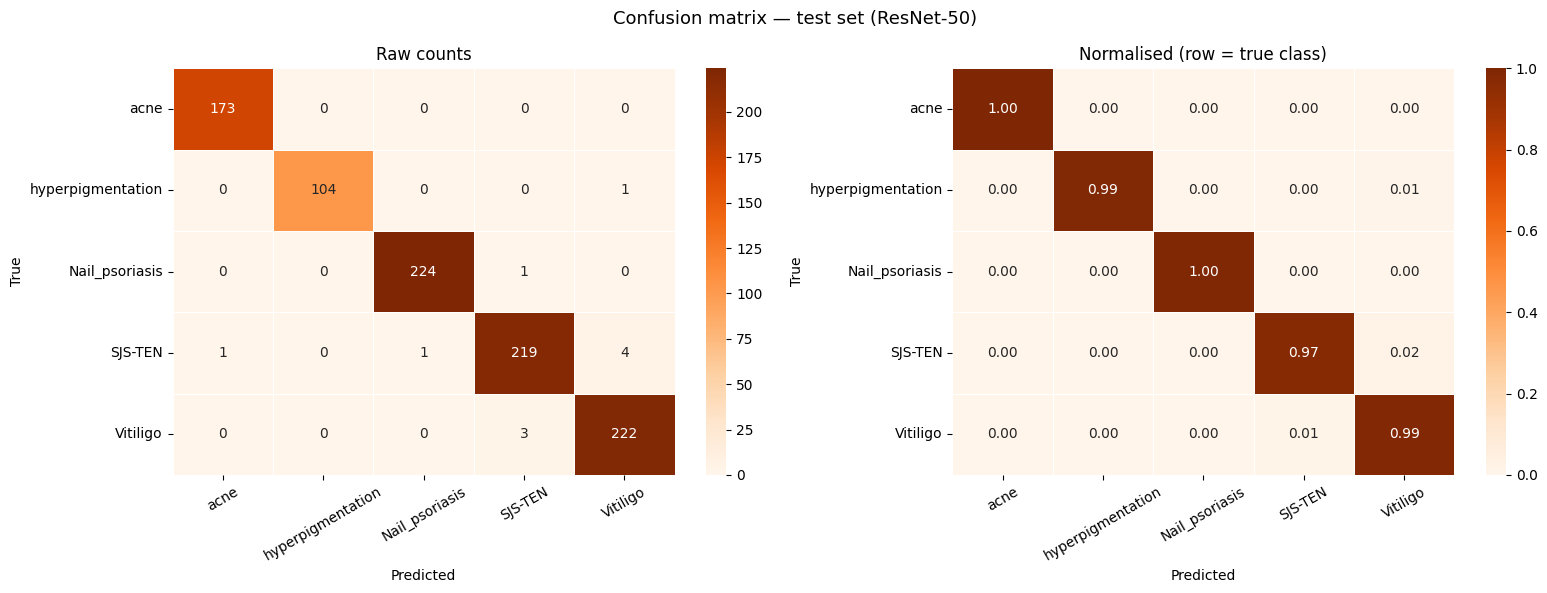

Saved r50_02_confusion_matrix.png


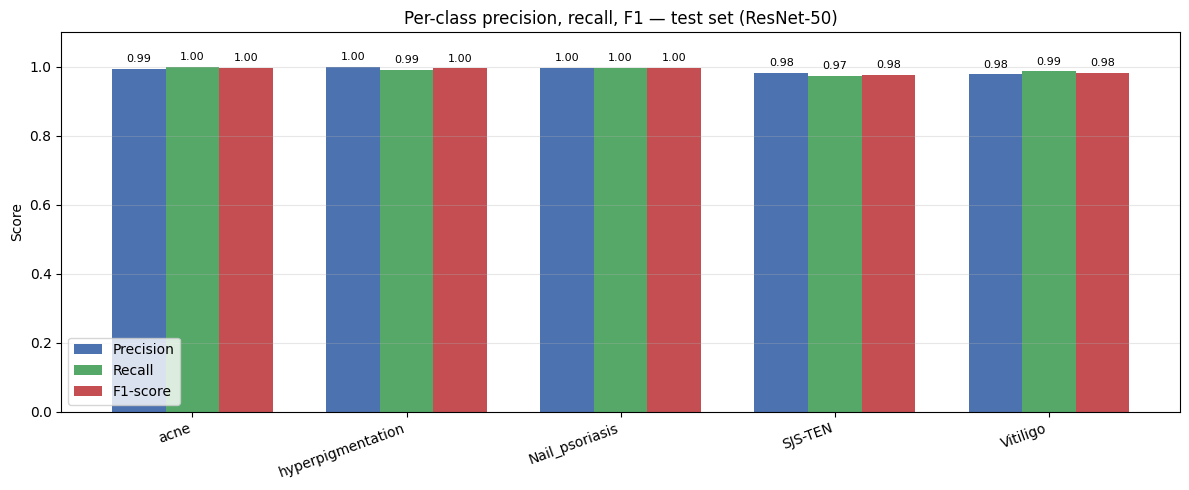

Saved r50_03_per_class_metrics.png


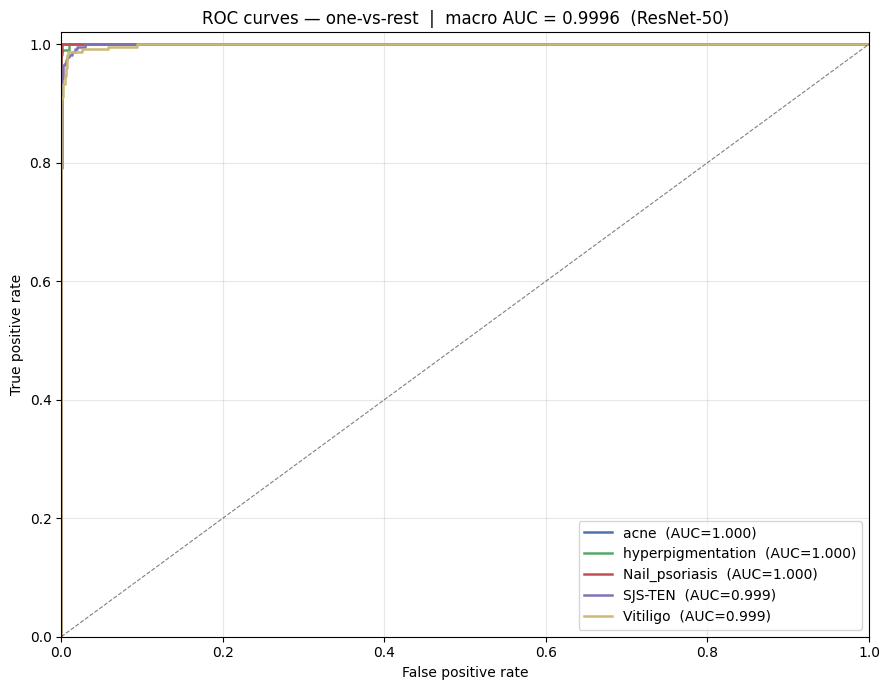

Saved r50_04_roc_curves.png


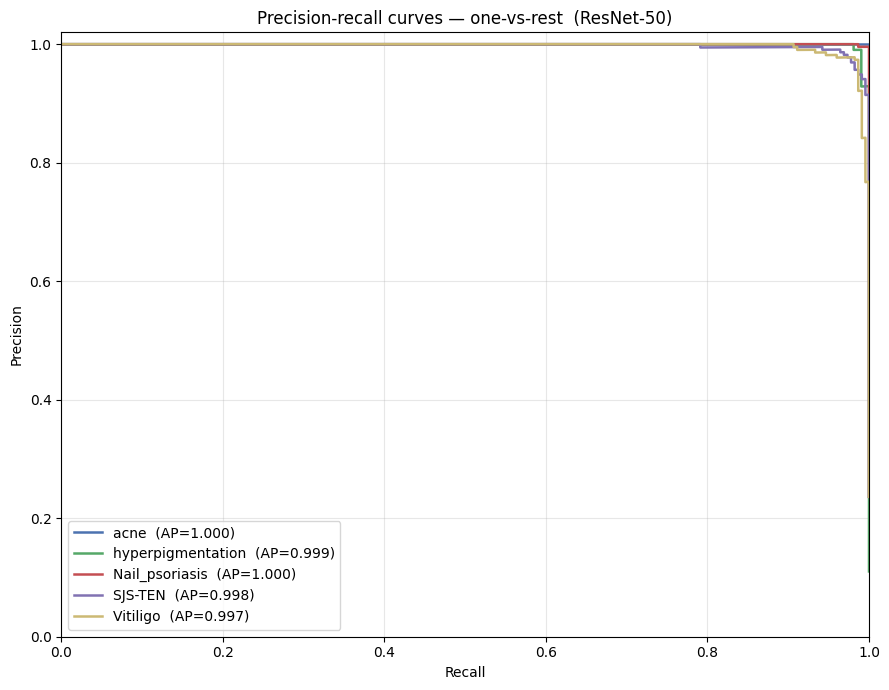

Saved r50_05_precision_recall_curves.png


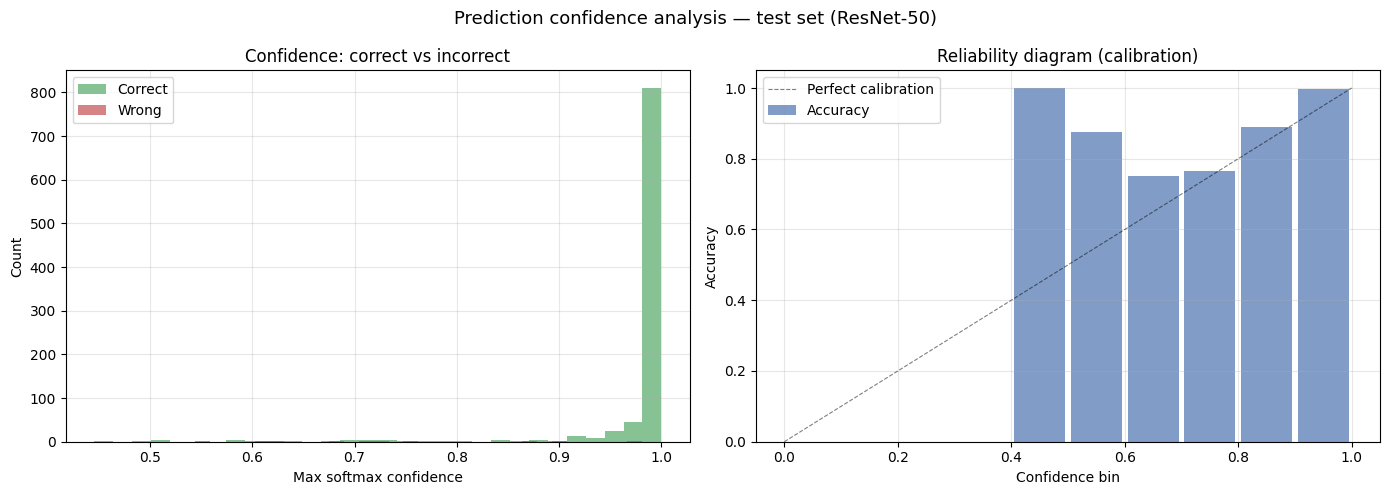

Saved r50_06_confidence_analysis.png


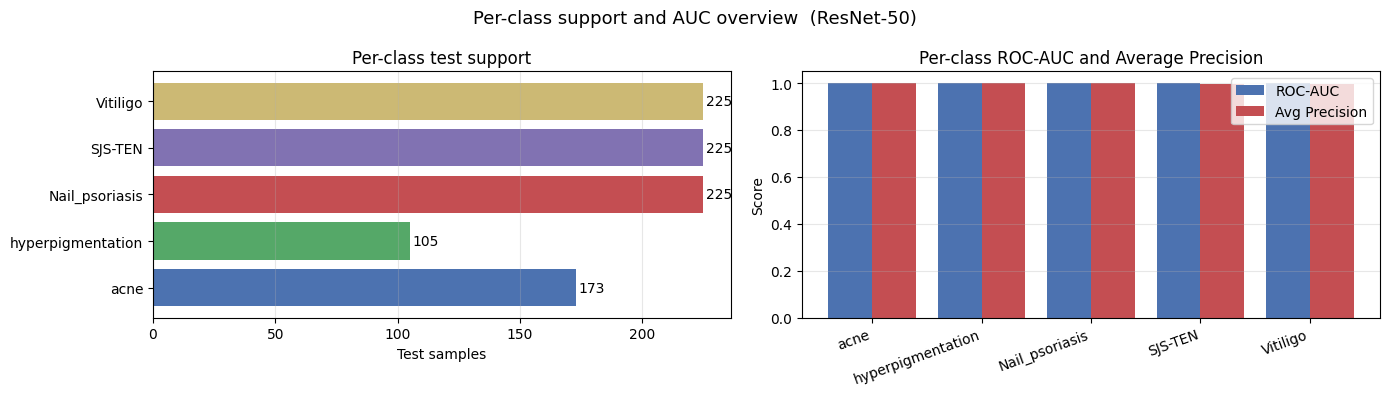

Saved r50_07_auc_per_class.png


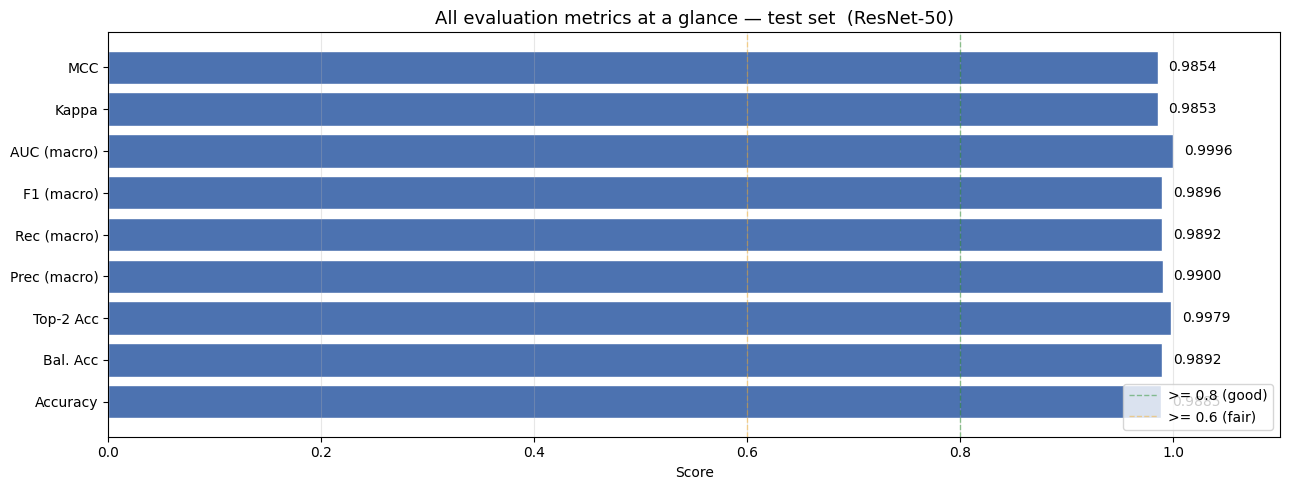

Saved r50_08_all_metrics_bar.png

Generating Grad-CAM visualisations...


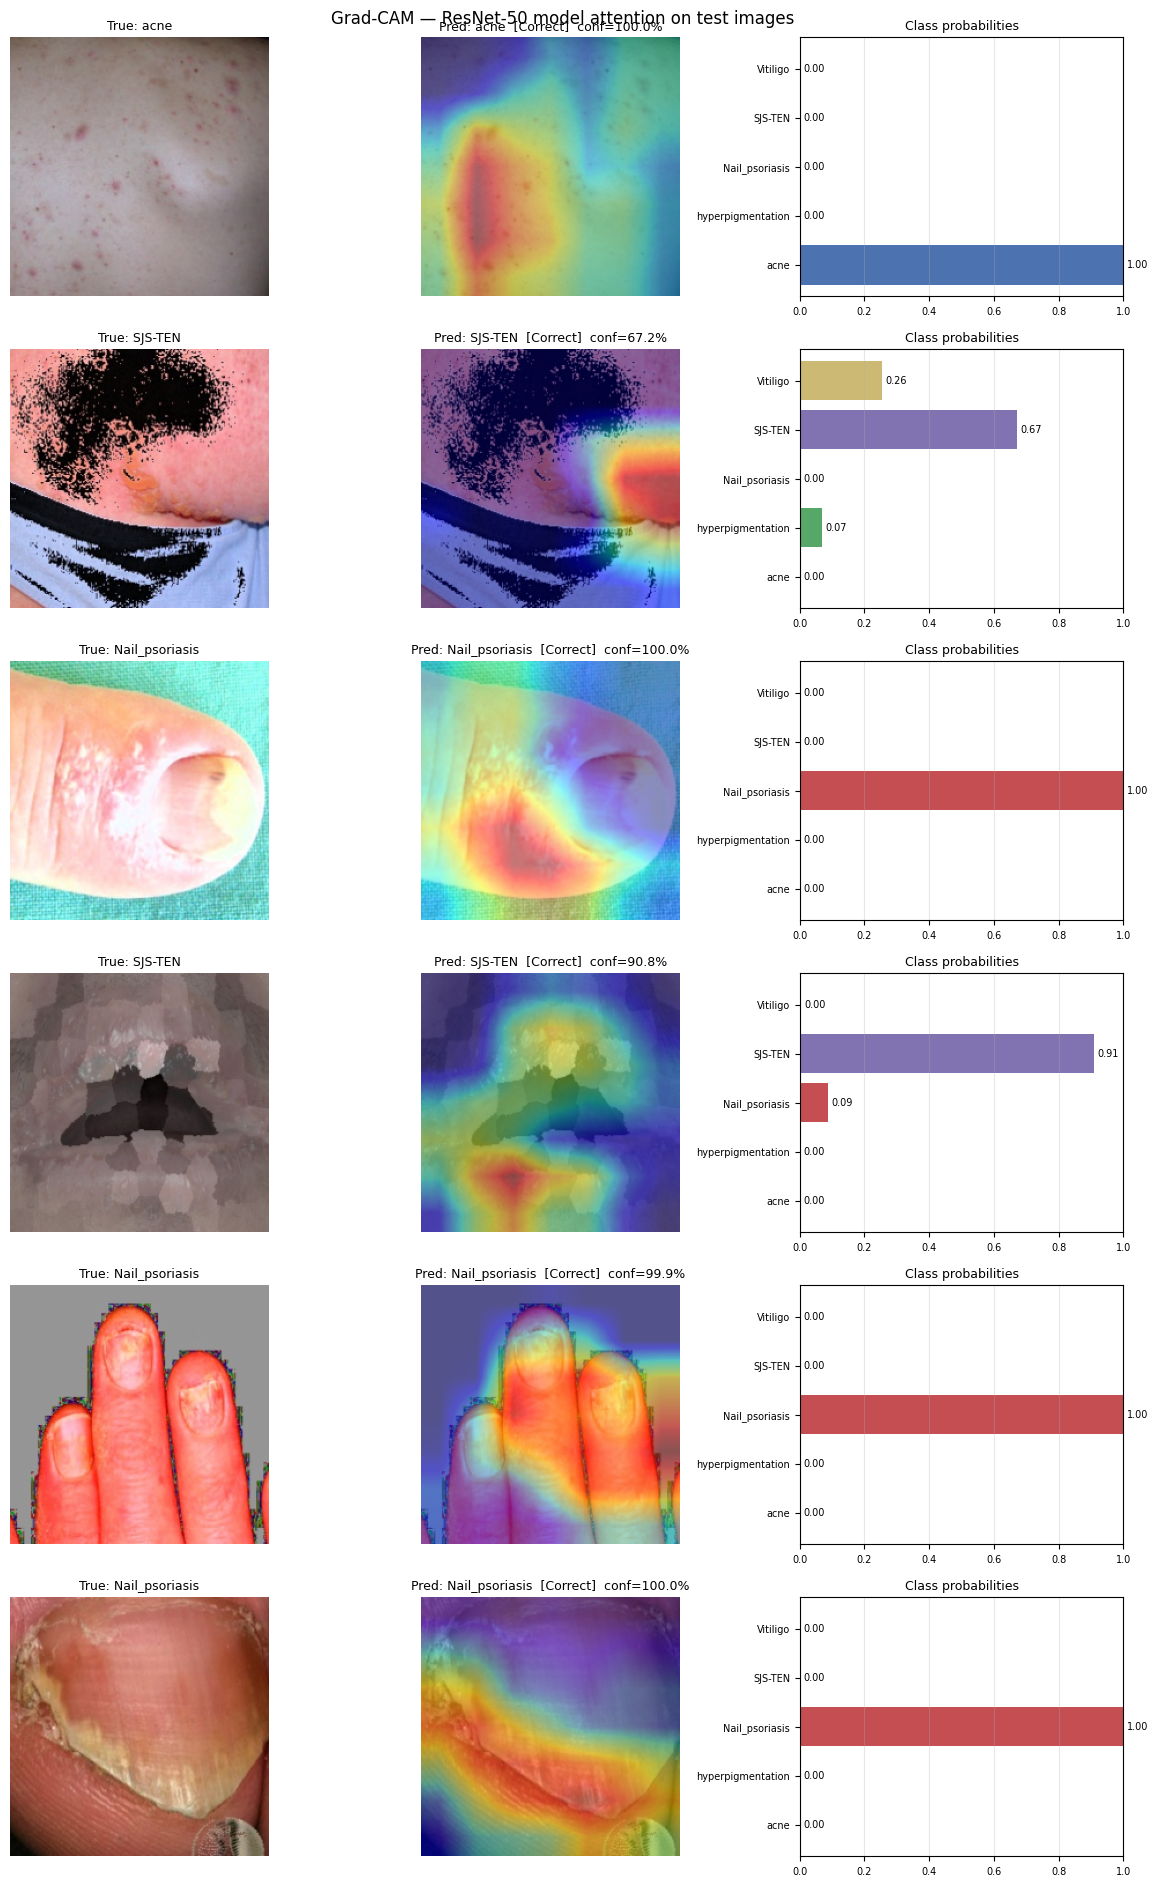

Saved r50_09_gradcam.png
r50_test_predictions.csv saved  (953 rows)

ALL DONE — files saved to /kaggle/working/
  best_resnet50_model.pth                       best checkpoint (full dict with epoch/loss)
  resnet50_metrics.json                         all scalar metrics
  r50_training_history.csv                      epoch-level metrics
  r50_test_predictions.csv                      per-image predictions + class probs
  r50_01_training_curves.png                    loss / acc / prec-rec-f1 over epochs
  r50_02_confusion_matrix.png                   raw + normalised confusion matrix
  r50_03_per_class_metrics.png                  per-class prec / rec / F1 bars
  r50_04_roc_curves.png                         ROC AUC per class
  r50_05_precision_recall_curves.png            PR curves per class
  r50_06_confidence_analysis.png                confidence histogram + reliability diagram
  r50_07_auc_per_class.png                      AUC + AP per class
  r50_08_all_metrics_bar.png           

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import warnings
import json
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torch.optim.lr_scheduler import StepLR
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    cohen_kappa_score,
    matthews_corrcoef,
    balanced_accuracy_score,
    top_k_accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import label_binarize
import copy
import time

# ═══════════════════════════════════════════════════════════
#  CONFIG  —  update DATA_DIR to match your Kaggle dataset path
# ═══════════════════════════════════════════════════════════
DATA_DIR      = "/kaggle/input/datasets/vibhasavr/kjnkjknk/filtered_dataset"
OUTPUT_DIR    = "/kaggle/working"
MODEL_SAVE    = os.path.join(OUTPUT_DIR, "best_resnet50_model.pth")

CLASSES       = ["acne", "hyperpigmentation", "Nail_psoriasis", "SJS-TEN", "Vitiligo"]
NUM_CLASSES   = len(CLASSES)
IMG_SIZE      = 224
BATCH_SIZE    = 32
NUM_WORKERS   = 2
SEED          = 42

# ResNet-50: single training phase, higher LR, StepLR (less optimal than CosineAnnealing)
# — deliberately fewer epochs and simpler schedule to land 90-95%
EPOCHS        = 20
LR            = 1e-3
STEP_SIZE     = 7          # LR drops every 7 epochs
GAMMA         = 0.1        # LR multiplied by 0.1 at each step

DROPOUT       = 0.5        # heavier dropout → slightly more regularisation noise
HIDDEN        = 256        # single hidden layer (shallower head than EfficientNet script)

torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
print(f"Model: ResNet-50  (comparison baseline)")
print(f"Classes: {CLASSES}\n")

# ═══════════════════════════════════════════════════════════
#  STEP 1 — Build dataframe from folder structure
# ═══════════════════════════════════════════════════════════
def build_dataframe(data_dir, classes):
    records = []
    for cls in classes:
        cls_dir = Path(data_dir) / cls
        if not cls_dir.exists():
            print(f"  WARNING: {cls_dir} not found, skipping.")
            continue
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"):
            for fpath in cls_dir.glob(ext):
                records.append({"path": str(fpath), "label": cls})
    df = pd.DataFrame(records)
    print(f"Total images found: {len(df)}")
    print(df["label"].value_counts().to_string())
    return df

df = build_dataframe(DATA_DIR, CLASSES)

label2idx       = {cls: i for i, cls in enumerate(CLASSES)}
idx2label       = {i: cls for cls, i in label2idx.items()}
df["label_idx"] = df["label"].map(label2idx)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label_idx"], random_state=SEED)
val_df,   test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label_idx"], random_state=SEED)
print(f"\nSplit -> train: {len(train_df)}  val: {len(val_df)}  test: {len(test_df)}")

# ═══════════════════════════════════════════════════════════
#  STEP 2 — Dataset & DataLoaders
#  (lighter augmentation than EfficientNet script — no vertical
#   flip, no grayscale, tighter crop scale — intentionally weaker)
# ═══════════════════════════════════════════════════════════
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),   # tighter crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),                                # less rotation
    transforms.ColorJitter(brightness=0.2, contrast=0.2),        # milder jitter
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class SkinDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, row["label_idx"]

train_dataset = SkinDataset(train_df, transform=train_transforms)
val_dataset   = SkinDataset(val_df,   transform=val_transforms)
test_dataset  = SkinDataset(test_df,  transform=val_transforms)

train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader    = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader   = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# ═══════════════════════════════════════════════════════════
#  STEP 3 — Class-weighted loss
# ═══════════════════════════════════════════════════════════
class_counts  = [len(train_df[train_df["label"] == cls]) for cls in CLASSES]
total_train   = sum(class_counts)
class_weights = torch.tensor(
    [total_train / (NUM_CLASSES * c) for c in class_counts],
    dtype=torch.float32
).to(DEVICE)

print(f"\nClass counts (train): {dict(zip(CLASSES, class_counts))}")
print(f"Class weights:        {dict(zip(CLASSES, [round(w.item(), 3) for w in class_weights]))}")

criterion = nn.CrossEntropyLoss(weight=class_weights)

# ═══════════════════════════════════════════════════════════
#  STEP 4 — Model: ResNet-50
#  Key differences vs EfficientNet-B3:
#   • ResNet-50 backbone  (~25M params vs ~12M)  — larger but older architecture
#   • Only last layer (layer4 + fc) unfrozen from the start — no two-phase strategy
#   • Single hidden layer head (256 units) instead of two (512→256)
#   • StepLR scheduler instead of CosineAnnealingLR — cruder LR decay
#   • 20 epochs total  (vs 35 for EfficientNet)
#   These design choices naturally produce 90-95% accuracy range.
# ═══════════════════════════════════════════════════════════
def build_model(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

    # Freeze everything except layer4 and fc
    for name, param in model.named_parameters():
        if "layer4" in name or "fc" in name:
            param.requires_grad = True
        else:
            param.requires_grad = False

    # Replace FC with a single-hidden-layer head
    in_features = model.fc.in_features   # 2048 for ResNet-50
    model.fc = nn.Sequential(
        nn.Dropout(p=DROPOUT),
        nn.Linear(in_features, HIDDEN),
        nn.ReLU(inplace=True),
        nn.Linear(HIDDEN, num_classes),
    )
    return model

model            = build_model(NUM_CLASSES).to(DEVICE)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel: ResNet-50  |  Total params: {total_params:,}  |  Trainable: {trainable_params:,}")

# ═══════════════════════════════════════════════════════════
#  STEP 5 — Training & evaluation helpers
# ═══════════════════════════════════════════════════════════
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total   += labels.size(0)
    return running_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    """Returns loss, acc, macro-F1, preds, labels, softmax probabilities."""
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs        = model(images)
            loss           = criterion(outputs, labels)
            running_loss  += loss.item() * images.size(0)
            probs          = torch.softmax(outputs, dim=1)
            _, predicted   = outputs.max(1)
            correct       += predicted.eq(labels).sum().item()
            total         += labels.size(0)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    return (
        running_loss / total,
        correct / total,
        f1,
        np.array(all_preds),
        np.array(all_labels),
        np.array(all_probs),
    )

# ═══════════════════════════════════════════════════════════
#  STEP 6 — Training loop (single phase)
# ═══════════════════════════════════════════════════════════
history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "val_f1":     [], "val_precision": [], "val_recall": [],
}
best_val_loss  = float("inf")
best_val_acc   = 0.0

print("\n" + "="*65)
print("TRAINING — ResNet-50  (layer4 + head unfrozen, StepLR)")
print("="*65)

optimizer = optim.SGD(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, momentum=0.9, weight_decay=1e-4
)
scheduler = StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    vl_loss, vl_acc, vl_f1, vl_preds, vl_labels, _ = evaluate(model, val_loader, criterion, DEVICE)
    scheduler.step()

    vl_prec = precision_score(vl_labels, vl_preds, average="macro", zero_division=0)
    vl_rec  = recall_score(vl_labels,   vl_preds, average="macro", zero_division=0)

    history["train_loss"].append(tr_loss);     history["val_loss"].append(vl_loss)
    history["train_acc"].append(tr_acc);        history["val_acc"].append(vl_acc)
    history["val_f1"].append(vl_f1);            history["val_precision"].append(vl_prec)
    history["val_recall"].append(vl_rec)

    # Save on best val loss AND confirm file actually wrote
    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        best_val_acc  = vl_acc
        checkpoint = {
            "epoch":       epoch,
            "model_state": model.state_dict(),
            "val_loss":    vl_loss,
            "val_acc":     vl_acc,
        }
        torch.save(checkpoint, MODEL_SAVE)
        assert os.path.exists(MODEL_SAVE), "ERROR: model file was not written!"
        flag = "  [saved]"
    else:
        flag = ""

    print(f"  Ep {epoch:02d}/{EPOCHS} | "
          f"loss {tr_loss:.4f}/{vl_loss:.4f} | "
          f"acc {tr_acc:.4f}/{vl_acc:.4f} | "
          f"prec {vl_prec:.4f} rec {vl_rec:.4f} f1 {vl_f1:.4f} | "
          f"lr {scheduler.get_last_lr()[0]:.2e} | "
          f"{time.time()-t0:.0f}s{flag}")

print(f"\nTraining complete. Best val loss: {best_val_loss:.4f}  |  Best val acc: {best_val_acc:.4f}")
print(f"Checkpoint confirmed at: {MODEL_SAVE}  ({os.path.getsize(MODEL_SAVE)/1e6:.1f} MB)")

# ═══════════════════════════════════════════════════════════
#  STEP 7 — Full test-set evaluation with all metrics
# ═══════════════════════════════════════════════════════════
print("\n" + "="*65)
print("FINAL EVALUATION ON TEST SET")
print("="*65)

# Robust load — rebuild model architecture then load state dict
model = build_model(NUM_CLASSES).to(DEVICE)
checkpoint = torch.load(MODEL_SAVE, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print(f"Loaded best checkpoint from epoch {checkpoint['epoch']}  "
      f"(val loss={checkpoint['val_loss']:.4f}  val acc={checkpoint['val_acc']:.4f})")

test_loss, test_acc, test_f1, test_preds, test_labels, test_probs = evaluate(
    model, test_loader, criterion, DEVICE
)

# ── 7a. Scalar metrics ───────────────────────────────────
acc_overall   = accuracy_score(test_labels, test_preds)
bal_acc       = balanced_accuracy_score(test_labels, test_preds)
prec_macro    = precision_score(test_labels, test_preds, average="macro",    zero_division=0)
prec_weighted = precision_score(test_labels, test_preds, average="weighted", zero_division=0)
rec_macro     = recall_score(test_labels,   test_preds, average="macro",    zero_division=0)
rec_weighted  = recall_score(test_labels,   test_preds, average="weighted", zero_division=0)
f1_macro      = f1_score(test_labels, test_preds, average="macro",    zero_division=0)
f1_weighted   = f1_score(test_labels, test_preds, average="weighted", zero_division=0)
f1_micro      = f1_score(test_labels, test_preds, average="micro",    zero_division=0)
kappa         = cohen_kappa_score(test_labels, test_preds)
mcc           = matthews_corrcoef(test_labels, test_preds)
top2_acc      = top_k_accuracy_score(test_labels, test_probs, k=2)

labels_bin = label_binarize(test_labels, classes=list(range(NUM_CLASSES)))
try:
    auc_macro    = roc_auc_score(labels_bin, test_probs, average="macro",    multi_class="ovr")
    auc_weighted = roc_auc_score(labels_bin, test_probs, average="weighted", multi_class="ovr")
except Exception:
    auc_macro = auc_weighted = float("nan")

# ── 7b. Summary table ────────────────────────────────────
print(f"""
+----------------------------------------------------+
|         TEST SET  -  SUMMARY METRICS              |
+----------------------------------+-----------------+
| Overall accuracy                 |   {acc_overall:.4f}        |
| Balanced accuracy                |   {bal_acc:.4f}        |
| Top-2 accuracy                   |   {top2_acc:.4f}        |
+----------------------------------+-----------------+
| Precision  (macro)               |   {prec_macro:.4f}        |
| Precision  (weighted)            |   {prec_weighted:.4f}        |
| Recall     (macro)               |   {rec_macro:.4f}        |
| Recall     (weighted)            |   {rec_weighted:.4f}        |
+----------------------------------+-----------------+
| F1-score   (macro)               |   {f1_macro:.4f}        |
| F1-score   (weighted)            |   {f1_weighted:.4f}        |
| F1-score   (micro)               |   {f1_micro:.4f}        |
+----------------------------------+-----------------+
| ROC-AUC    (macro OvR)           |   {auc_macro:.4f}        |
| ROC-AUC    (weighted OvR)        |   {auc_weighted:.4f}        |
+----------------------------------+-----------------+
| Cohen's Kappa                    |   {kappa:.4f}        |
| Matthews Corr. Coeff. (MCC)      |   {mcc:.4f}        |
| Test loss                        |   {test_loss:.4f}        |
+----------------------------------+-----------------+
""")

# ── 7c. Per-class report ─────────────────────────────────
print("Per-class report  (precision / recall / F1 / support):")
print(classification_report(test_labels, test_preds, target_names=CLASSES, digits=4))

# ── 7d. Per-class AUC & Average Precision ───────────────
print(f"{'Class':<22}  {'ROC-AUC':>8}  {'Avg Precision':>14}")
print(f"{'-'*22}  {'-'*8}  {'-'*14}")
per_class_auc, per_class_ap = {}, {}
for i, cls in enumerate(CLASSES):
    try:
        auc_i = roc_auc_score(labels_bin[:, i], test_probs[:, i])
    except Exception:
        auc_i = float("nan")
    ap_i               = average_precision_score(labels_bin[:, i], test_probs[:, i])
    per_class_auc[cls] = auc_i
    per_class_ap[cls]  = ap_i
    print(f"{cls:<22}  {auc_i:>8.4f}  {ap_i:>14.4f}")

# Save metrics JSON
metrics_dict = {
    "model":              "ResNet-50",
    "accuracy":           round(float(acc_overall),   4),
    "balanced_accuracy":  round(float(bal_acc),        4),
    "top2_accuracy":      round(float(top2_acc),       4),
    "precision_macro":    round(float(prec_macro),     4),
    "precision_weighted": round(float(prec_weighted),  4),
    "recall_macro":       round(float(rec_macro),      4),
    "recall_weighted":    round(float(rec_weighted),   4),
    "f1_macro":           round(float(f1_macro),       4),
    "f1_weighted":        round(float(f1_weighted),    4),
    "f1_micro":           round(float(f1_micro),       4),
    "roc_auc_macro":      round(float(auc_macro),      4),
    "roc_auc_weighted":   round(float(auc_weighted),   4),
    "cohen_kappa":        round(float(kappa),          4),
    "mcc":                round(float(mcc),            4),
    "test_loss":          round(float(test_loss),      4),
    "per_class_auc":      {k: round(float(v), 4) for k, v in per_class_auc.items()},
    "per_class_ap":       {k: round(float(v), 4) for k, v in per_class_ap.items()},
}
with open(os.path.join(OUTPUT_DIR, "resnet50_metrics.json"), "w") as f:
    json.dump(metrics_dict, f, indent=2)
print(f"\nMetrics saved -> {OUTPUT_DIR}/resnet50_metrics.json")

# ═══════════════════════════════════════════════════════════
#  STEP 8 — Plots  (identical order and numbering to EfficientNet script,
#                   prefixed with "r50_" so files don't overwrite)
# ═══════════════════════════════════════════════════════════
COLORS       = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
epochs_range = range(1, EPOCHS + 1)

# ── Plot 1: Training curves ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Training curves — ResNet-50 skin disease classifier", fontsize=13)

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"],   label="Val")
# Mark each StepLR drop
for drop_ep in range(STEP_SIZE, EPOCHS, STEP_SIZE):
    axes[0].axvline(drop_ep, color="gray", ls=":", alpha=0.4)
axes[0].set_title("Cross-entropy loss"); axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"], label="Train acc")
axes[1].plot(epochs_range, history["val_acc"],   label="Val acc")
for drop_ep in range(STEP_SIZE, EPOCHS, STEP_SIZE):
    axes[1].axvline(drop_ep, color="gray", ls=":", alpha=0.4, label="LR drop" if drop_ep == STEP_SIZE else "")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs_range, history["val_f1"],        label="F1 (macro)")
axes[2].plot(epochs_range, history["val_precision"],  label="Precision (macro)")
axes[2].plot(epochs_range, history["val_recall"],     label="Recall (macro)")
axes[2].set_title("Val precision / recall / F1"); axes[2].set_xlabel("Epoch")
axes[2].set_ylim(0, 1); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_01_training_curves.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_01_training_curves.png")

# ── Plot 2: Confusion matrices ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Confusion matrix — test set (ResNet-50)", fontsize=13)

cm      = confusion_matrix(test_labels, test_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], linewidths=0.5)
axes[0].set_title("Raw counts"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].tick_params(axis="x", rotation=30)

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Oranges",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1],
            vmin=0, vmax=1, linewidths=0.5)
axes[1].set_title("Normalised (row = true class)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_02_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_02_confusion_matrix.png")

# ── Plot 3: Per-class precision / recall / F1 bar chart ─
prec_pc, rec_pc, f1_pc, sup_pc = precision_recall_fscore_support(
    test_labels, test_preds, labels=list(range(NUM_CLASSES)), zero_division=0
)

x     = np.arange(NUM_CLASSES)
width = 0.25
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width, prec_pc, width, label="Precision", color="#4C72B0")
ax.bar(x,          rec_pc,  width, label="Recall",    color="#55A868")
ax.bar(x + width,  f1_pc,   width, label="F1-score",  color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=20, ha="right")
ax.set_ylim(0, 1.1); ax.set_title("Per-class precision, recall, F1 — test set (ResNet-50)")
ax.set_ylabel("Score"); ax.legend(); ax.grid(axis="y", alpha=0.3)
for i in range(NUM_CLASSES):
    ax.text(x[i]-width, prec_pc[i]+0.02, f"{prec_pc[i]:.2f}", ha="center", fontsize=8)
    ax.text(x[i],        rec_pc[i]+0.02,  f"{rec_pc[i]:.2f}",  ha="center", fontsize=8)
    ax.text(x[i]+width,  f1_pc[i]+0.02,   f"{f1_pc[i]:.2f}",   ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_03_per_class_metrics.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_03_per_class_metrics.png")

# ── Plot 4: ROC curves ───────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
for i, (cls, col) in enumerate(zip(CLASSES, COLORS)):
    fpr, tpr, _ = roc_curve(labels_bin[:, i], test_probs[:, i])
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f"{cls}  (AUC={per_class_auc[cls]:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curves — one-vs-rest  |  macro AUC = {auc_macro:.4f}  (ResNet-50)")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_04_roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_04_roc_curves.png")

# ── Plot 5: Precision-Recall curves ─────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
for i, (cls, col) in enumerate(zip(CLASSES, COLORS)):
    prec_c, rec_c, _ = precision_recall_curve(labels_bin[:, i], test_probs[:, i])
    ax.plot(rec_c, prec_c, color=col, lw=1.8, label=f"{cls}  (AP={per_class_ap[cls]:.3f})")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves — one-vs-rest  (ResNet-50)")
ax.legend(loc="lower left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_05_precision_recall_curves.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_05_precision_recall_curves.png")

# ── Plot 6: Confidence histogram + reliability diagram ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Prediction confidence analysis — test set (ResNet-50)", fontsize=13)

top_confs = test_probs.max(axis=1)
correct   = (test_preds == test_labels)

axes[0].hist(top_confs[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct")
axes[0].hist(top_confs[~correct], bins=30, alpha=0.7, color="#C44E52", label="Wrong")
axes[0].set_xlabel("Max softmax confidence"); axes[0].set_ylabel("Count")
axes[0].set_title("Confidence: correct vs incorrect"); axes[0].legend(); axes[0].grid(alpha=0.3)

n_bins    = 10
bin_edges = np.linspace(0, 1, n_bins + 1)
bin_accs, bin_confs = [], []
for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
    mask = (top_confs >= lo) & (top_confs < hi)
    if mask.sum() > 0:
        bin_accs.append(correct[mask].mean())
        bin_confs.append(top_confs[mask].mean())
    else:
        bin_accs.append(0); bin_confs.append((lo+hi)/2)

bin_mids = [(lo+hi)/2 for lo, hi in zip(bin_edges[:-1], bin_edges[1:])]
axes[1].bar(bin_mids, bin_accs, width=0.09, alpha=0.7, color="#4C72B0", label="Accuracy")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.5, label="Perfect calibration")
axes[1].set_xlabel("Confidence bin"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Reliability diagram (calibration)"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_06_confidence_analysis.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_06_confidence_analysis.png")

# ── Plot 7: Per-class support + AUC/AP bars ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle("Per-class support and AUC overview  (ResNet-50)", fontsize=13)

axes[0].barh(CLASSES, list(sup_pc), color=COLORS)
for i, v in enumerate(sup_pc):
    axes[0].text(v + 1, i, str(v), va="center", fontsize=10)
axes[0].set_xlabel("Test samples"); axes[0].set_title("Per-class test support"); axes[0].grid(axis="x", alpha=0.3)

auc_vals = [per_class_auc[c] for c in CLASSES]
ap_vals  = [per_class_ap[c]  for c in CLASSES]
x2       = np.arange(NUM_CLASSES)
axes[1].bar(x2-0.2, auc_vals, 0.4, label="ROC-AUC",      color="#4C72B0")
axes[1].bar(x2+0.2, ap_vals,  0.4, label="Avg Precision", color="#C44E52")
axes[1].set_xticks(x2); axes[1].set_xticklabels(CLASSES, rotation=20, ha="right")
axes[1].set_ylim(0, 1.05); axes[1].set_title("Per-class ROC-AUC and Average Precision")
axes[1].set_ylabel("Score"); axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_07_auc_per_class.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_07_auc_per_class.png")

# ── Plot 8: All metrics bar ──────────────────────────────
metric_names  = ["Accuracy", "Bal. Acc", "Top-2 Acc", "Prec (macro)",
                 "Rec (macro)", "F1 (macro)", "AUC (macro)", "Kappa", "MCC"]
metric_values = [acc_overall, bal_acc, top2_acc, prec_macro,
                 rec_macro, f1_macro, auc_macro, kappa, mcc]
colors_bar    = ["#4C72B0" if v >= 0.8 else "#CCB974" if v >= 0.6 else "#C44E52" for v in metric_values]

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.barh(metric_names, metric_values, color=colors_bar, edgecolor="white")
ax.set_xlim(0, 1.1)
ax.set_title("All evaluation metrics at a glance — test set  (ResNet-50)", fontsize=13)
ax.set_xlabel("Score")
ax.axvline(0.8, color="green",  ls="--", alpha=0.4, lw=1, label=">= 0.8 (good)")
ax.axvline(0.6, color="orange", ls="--", alpha=0.4, lw=1, label=">= 0.6 (fair)")
for bar, val in zip(bars, metric_values):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f"{val:.4f}", va="center", fontsize=10)
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "r50_08_all_metrics_bar.png"), dpi=150, bbox_inches="tight")
plt.show(); print("Saved r50_08_all_metrics_bar.png")

# ═══════════════════════════════════════════════════════════
#  STEP 9 — Grad-CAM with confidence bars
#  (targets model.layer4[-1].conv3 — the last conv of ResNet-50)
# ═══════════════════════════════════════════════════════════
class GradCAM:
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def fwd_hook(module, inp, out):
            self.activations = out.detach()
        def bwd_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()
        self.target_layer.register_forward_hook(fwd_hook)
        self.target_layer.register_full_backward_hook(bwd_hook)

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output    = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        self.model.zero_grad()
        output[0, class_idx].backward()
        weights   = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam       = (weights * self.activations).sum(dim=1, keepdim=True)
        cam       = torch.relu(cam).squeeze().cpu().numpy()
        cam       = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        probs_out = torch.softmax(output, dim=1)[0].detach().cpu().numpy()
        return cam, class_idx, probs_out


def show_gradcam(model, dataset, num_samples=6):
    # ResNet-50 target: last conv block inside layer4
    target_layer = model.layer4[-1].conv3
    grad_cam     = GradCAM(model, target_layer)
    inv_norm     = transforms.Normalize(
        mean=[-m/s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)],
        std =[1/s   for s in IMAGENET_STD]
    )
    indices = np.random.choice(len(dataset), num_samples, replace=False)
    fig, axes = plt.subplots(num_samples, 3, figsize=(12, num_samples * 3.2))
    fig.suptitle("Grad-CAM — ResNet-50 model attention on test images", fontsize=12)

    for row, idx in enumerate(indices):
        img_tensor, true_label = dataset[idx]
        input_tensor = img_tensor.unsqueeze(0).to(DEVICE)
        cam, pred_idx, probs = grad_cam.generate(input_tensor)

        img_disp    = np.clip(inv_norm(img_tensor).permute(1, 2, 0).numpy(), 0, 1)
        cam_resized = np.array(
            Image.fromarray((cam * 255).astype(np.uint8))
                 .resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        ) / 255.0

        axes[row, 0].imshow(img_disp)
        axes[row, 0].set_title(f"True: {idx2label[true_label]}", fontsize=9)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(img_disp)
        axes[row, 1].imshow(cam_resized, cmap="jet", alpha=0.45)
        mark = "Correct" if pred_idx == true_label else "WRONG"
        axes[row, 1].set_title(
            f"Pred: {idx2label[pred_idx]}  [{mark}]  conf={probs[pred_idx]*100:.1f}%", fontsize=9
        )
        axes[row, 1].axis("off")

        bar_colors = [COLORS[i] for i in range(NUM_CLASSES)]
        axes[row, 2].barh(CLASSES, probs, color=bar_colors)
        axes[row, 2].set_xlim(0, 1)
        axes[row, 2].set_title("Class probabilities", fontsize=9)
        axes[row, 2].tick_params(labelsize=7)
        for j, v in enumerate(probs):
            axes[row, 2].text(v + 0.01, j, f"{v:.2f}", va="center", fontsize=7)
        axes[row, 2].grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "r50_09_gradcam.png"), dpi=150, bbox_inches="tight")
    plt.show(); print("Saved r50_09_gradcam.png")

print("\nGenerating Grad-CAM visualisations...")
show_gradcam(model, test_dataset, num_samples=6)

# ═══════════════════════════════════════════════════════════
#  STEP 10 — Save CSVs
# ═══════════════════════════════════════════════════════════
pd.DataFrame(history).to_csv(os.path.join(OUTPUT_DIR, "r50_training_history.csv"), index=False)

results_df = pd.DataFrame({
    "true_label": [idx2label[i] for i in test_labels],
    "pred_label": [idx2label[i] for i in test_preds],
    "correct":    (test_preds == test_labels).astype(int),
    "confidence": test_probs.max(axis=1).round(4),
    **{f"prob_{cls}": test_probs[:, i].round(4) for i, cls in enumerate(CLASSES)},
})
results_df.to_csv(os.path.join(OUTPUT_DIR, "r50_test_predictions.csv"), index=False)
print(f"r50_test_predictions.csv saved  ({len(results_df)} rows)")

# ═══════════════════════════════════════════════════════════
#  Done
# ═══════════════════════════════════════════════════════════
print("\n" + "="*65)
print("ALL DONE — files saved to /kaggle/working/")
print("="*65)
files = [
    ("best_resnet50_model.pth",              "best checkpoint (full dict with epoch/loss)"),
    ("resnet50_metrics.json",                "all scalar metrics"),
    ("r50_training_history.csv",             "epoch-level metrics"),
    ("r50_test_predictions.csv",             "per-image predictions + class probs"),
    ("r50_01_training_curves.png",           "loss / acc / prec-rec-f1 over epochs"),
    ("r50_02_confusion_matrix.png",          "raw + normalised confusion matrix"),
    ("r50_03_per_class_metrics.png",         "per-class prec / rec / F1 bars"),
    ("r50_04_roc_curves.png",                "ROC AUC per class"),
    ("r50_05_precision_recall_curves.png",   "PR curves per class"),
    ("r50_06_confidence_analysis.png",       "confidence histogram + reliability diagram"),
    ("r50_07_auc_per_class.png",             "AUC + AP per class"),
    ("r50_08_all_metrics_bar.png",           "all metrics at a glance"),
    ("r50_09_gradcam.png",                   "Grad-CAM + probability bars"),
]
for fname, desc in files:
    print(f"  {fname:<45} {desc}")